# Employee Wellness Analysis
### Exploratory Data Analysis of Mental Health & Treatment-Seeking Patterns at XYZ Technical Solutions

**Dataset:** 1,048 employee survey responses · 28 attributes  
**Target variable:** `treatment` (has the respondent sought mental health treatment? Yes / No)

---

## Table of Contents
1. [Business Context & Objectives](#1.-Business-Context-&-Objectives)
2. [Dataset Overview](#2.-Dataset-Overview)
3. [Data Preprocessing](#3.-Data-Preprocessing)
4. [Exploratory Data Analysis](#4.-Exploratory-Data-Analysis)
5. [Key Insights](#5.-Key-Insights)
6. [Recommendations](#6.-Recommendations)
7. [Limitations & Next Steps](#7.-Limitations-&-Next-Steps)

## 1. Business Context & Objectives

XYZ Technical Solutions recently lost an important employee to a health crisis. Leadership now wants to **proactively identify employees who need, or may soon need, mental health support**, and to design wellness programs that genuinely help.

This notebook analyses a public workplace mental-health survey to answer:

| # | Question |
|---|----------|
| 1 | Who is in the sample (age, gender, geography)? |
| 2 | How common is treatment-seeking overall? |
| 3 | Which factors (family history, work interference, company size, benefits awareness, ...) are most associated with treatment-seeking? |
| 4 | What practical steps can XYZ take based on these patterns? |

**Approach:** Understand the data → clean it → explore it visually → interpret findings → recommend actions.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# ---- Global style -----------------------------------------------------------
PRIMARY, ACCENT, WARM = "#028090", "#00A896", "#F2A65A"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (9, 5), "figure.dpi": 110,
    "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)

DATA_PATH = "employee_wellness_dataset.csv"   # adjust if the file lives elsewhere

## 2. Dataset Overview

The survey captures four groups of information:

| Group | Columns |
|---|---|
| **Demographics** | `Age`, `Gender`, `Country`, `state` |
| **Workplace factors** | `no_employees`, `remote_work`, `tech_company`, `self_employed` |
| **Employer support** | `benefits`, `care_options`, `wellness_program`, `seek_help`, `anonymity`, `leave` |
| **Attitudes & outcomes** | `family_history`, `work_interfere`, `mental_health_consequence`, `phys_health_consequence`, `coworkers`, `supervisor`, `mental_health_interview`, `phys_health_interview`, `mental_vs_physical`, `obs_consequence`, **`treatment`** |

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 1,048 rows x 28 columns


,S.No,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,1,8/27/2014 11:29,37,Female,United States,IL,NaN,No,Yes,Often,25-Jun,No,Yes,Yes,Not sure,No,Yes,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2,8/27/2014 11:29,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,No,No,Don't know,No,Don't know,Don't know,Don't know,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,3,8/27/2014 11:29,32,Male,Canada,NaN,NaN,No,No,Rarely,25-Jun,No,Yes,No,No,No,No,Don't know,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,4,8/27/2014 11:29,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,No,Yes,No,Yes,No,No,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,5,8/27/2014 11:30,31,Male,United States,TX,NaN,No,No,Never,100-500,Yes,Yes,Yes,No,Don't know,Don't know,Don't know,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048 entries, 0 to 1047
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   S.No                       1048 non-null   int64
 1   Timestamp                  1048 non-null   str  
 2   Age                        1048 non-null   int64
 3   Gender                     1048 non-null   str  
 4   Country                    1048 non-null   str  
 5   state                      636 non-null    str  
 6   self_employed              1030 non-null   str  
 7   family_history             1048 non-null   str  
 8   treatment                  1048 non-null   str  
 9   work_interfere             812 non-null    str  
 10  no_employees               1048 non-null   str  
 11  remote_work                1048 non-null   str  
 12  tech_company               1048 non-null   str  
 13  benefits                   1035 non-null   str  
 14  care_options               1048 non

In [4]:
# Missing values and duplicates in the raw file
missing = (df.isna().sum().rename("missing")
             .to_frame().assign(pct=lambda d: d["missing"] / len(df) * 100)
             .query("missing > 0").sort_values("missing", ascending=False))
display(missing)
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


,missing,pct
comments,916,87.40
state,412,39.31
work_interfere,236,22.52
self_employed,18,1.72
benefits,13,1.24
wellness_program,4,0.38
leave,4,0.38


In [5]:
# Spot the data-quality problems in the raw file
print("Raw Age range:", df["Age"].min(), "to", df["Age"].max())
print("Distinct raw Gender spellings:", df["Gender"].str.strip().str.lower().nunique())
print("no_employees values:", df["no_employees"].unique().tolist())

Raw Age range: -1726 to 99999999999
Distinct raw Gender spellings: 37
no_employees values: ['25-Jun', 'More than 1000', '26-100', '100-500', '5-Jan', '500-1000']


**Initial findings (raw data)**

- `Age` contains impossible values (negative ages, `99999999999`, and implausible entries such as 5 and 329).
- `Gender` is free text with dozens of spellings.
- `no_employees` has two labels corrupted by Excel's auto-date conversion (`25-Jun`, `5-Jan`).
- `state` (~39%), `work_interfere` (~23%) and `comments` (~87%) have substantial missing data.
- There are **no duplicate rows**.

## 3. Data Preprocessing

Five deliberate steps, each documented below. Original columns are preserved; cleaned versions are added alongside (`*_clean`) so the work stays auditable.

### Step 1 · Age outliers
Ages outside a realistic working range (18–75) are treated as **missing** rather than guessed.

In [6]:
VALID_AGE = (18, 75)
valid = df["Age"].between(*VALID_AGE)
df["Age_clean"] = df["Age"].where(valid)

print("Invalid ages flagged:", (~valid).sum())
print(df.loc[~valid, "Age"].tolist())
df["Age_clean"].describe()

Invalid ages flagged: 6
[-29, 329, 99999999999, -1726, 5, 8]


count   1,042.00
mean       31.92
std         7.22
min        18.00
25%        27.00
50%        31.00
75%        36.00
max        65.00
Name: Age_clean, dtype: float64

### Step 2 · Standardise gender
Free-text responses are collapsed into three analysable groups: **Male**, **Female**, **Other/Non-binary**.

In [7]:
MALE = {"male","m","male-ish","maile","cis male","mal","make","man","msle","mail","malr",
        "male (cis)","guy (-ish) ^_^","something kinda male?","male leaning androgynous"}
FEMALE = {"female","f","cis female","woman","femake","trans woman","female (trans)",
          "trans-female","female (cis)","cis-female/femme"}

def clean_gender(g):
    g = str(g).strip().lower()
    if g in MALE:   return "Male"
    if g in FEMALE: return "Female"
    return "Other/Non-binary"

df["Gender_clean"] = df["Gender"].apply(clean_gender)
df["Gender_clean"].value_counts()

Gender_clean
Male                830
Female              206
Other/Non-binary     12
Name: count, dtype: int64

### Step 3 · Repair corrupted company-size labels
Excel silently converted `6-25` → `25-Jun` and `1-5` → `5-Jan`. We restore them and apply an **ordered** categorical so charts sort logically.

In [8]:
FIX = {"25-Jun": "6-25", "5-Jan": "1-5"}
ORDER_SIZE = ["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"]

df["no_employees_clean"] = pd.Categorical(
    df["no_employees"].replace(FIX), categories=ORDER_SIZE, ordered=True)
df["no_employees_clean"].value_counts().sort_index()

no_employees_clean
1-5               133
6-25              245
26-100            238
100-500           150
500-1000           55
More than 1000    227
Name: count, dtype: int64

### Step 4 · Missing values

| Column | Treatment | Rationale |
|---|---|---|
| `self_employed` | Fill with mode (`No`) | Only a handful missing; `No` dominates |
| `work_interfere` | Label as `Not Applicable` | Blank means *no condition*, not unknown data |
| `comments` | Drop | ~87% empty, free text |
| `state` | Keep as-is | Only applicable to US respondents |

In [9]:
df["self_employed"] = df["self_employed"].fillna("No")
df["work_interfere_clean"] = df["work_interfere"].fillna("Not Applicable")
df = df.drop(columns=["comments"])

print("self_employed missing:", df["self_employed"].isna().sum())
print("Duplicate rows:", df.duplicated().sum())

self_employed missing: 0
Duplicate rows: 0


### Step 5 · Validation
A final sanity check that the cleaned dataset is analysis-ready.

In [10]:
summary = pd.Series({
    "Rows": len(df),
    "Columns": df.shape[1],
    "Age (clean) min / median / max": f"{df['Age_clean'].min():.0f} / {df['Age_clean'].median():.0f} / {df['Age_clean'].max():.0f}",
    "Gender categories": df["Gender_clean"].nunique(),
    "Company-size categories": df["no_employees_clean"].nunique(),
    "Treatment rate (%)": round((df["treatment"] == "Yes").mean() * 100, 1),
}, name="Cleaned dataset").to_frame()
summary

,Cleaned dataset
Rows,1048
Columns,31
Age (clean) min / median / max,18 / 31 / 65
Gender categories,3
Company-size categories,6
Treatment rate (%),48.90


## 4. Exploratory Data Analysis

Helper functions keep the charts consistent. Each section ends with the **insight** it supports.

In [11]:
def treatment_rate(frame, col, order=None):
    """Percentage of each group that has sought treatment, plus group size."""
    g = frame.groupby(col, observed=True)["treatment"]
    out = pd.DataFrame({"n": g.size(), "treatment_rate_%": g.apply(lambda s: (s == "Yes").mean() * 100)})
    return out.reindex(order) if order is not None else out

def chi2_report(frame, col):
    """Chi-square test of independence between `col` and treatment."""
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(frame[col], frame["treatment"]))
    print(f"{col}: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2g}")

def bar_labels(ax, fmt="{:.0f}"):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) for v in c.datavalues], padding=2, fontsize=9)

### 4.1 Age distribution

Respondents aged 25-34: 56.9%


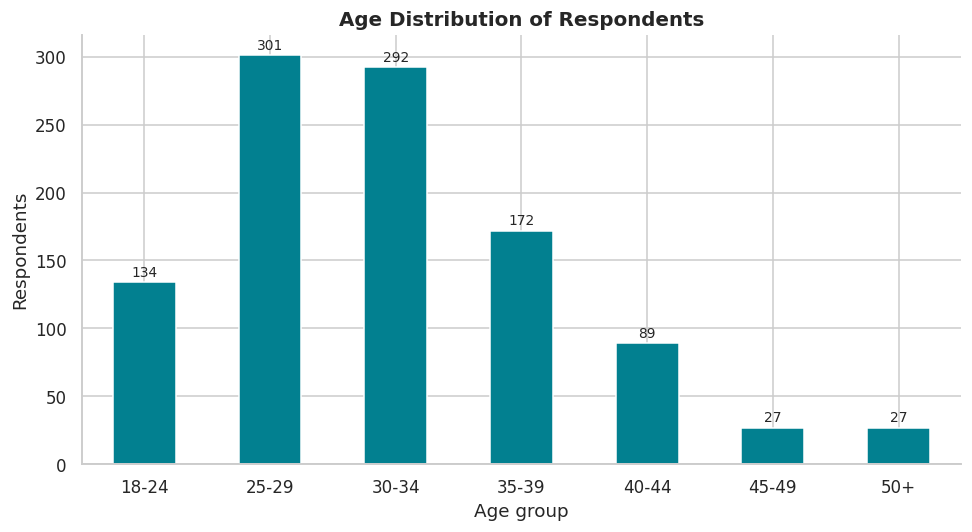

In [12]:
bins   = [17, 24, 29, 34, 39, 44, 49, 75]
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50+"]
df["age_bin"] = pd.cut(df["Age_clean"], bins=bins, labels=labels)

counts = df["age_bin"].value_counts().reindex(labels)
ax = counts.plot(kind="bar", color=PRIMARY, rot=0)
ax.set(title="Age Distribution of Respondents", xlabel="Age group", ylabel="Respondents")
bar_labels(ax)
plt.tight_layout(); plt.show()

share_25_34 = counts[["25-29", "30-34"]].sum() / counts.sum() * 100
print(f"Respondents aged 25-34: {share_25_34:.1f}%")

> **Insight:** The workforce is **young**: about 57% of respondents are between 25 and 34, a career stage often marked by rising workload and career-establishment stress, so early wellness intervention is especially valuable.

### 4.2 Gender distribution

Gender_clean
Male                79.2 %
Female              19.7 %
Other/Non-binary     1.1 %
Name: count, dtype: str


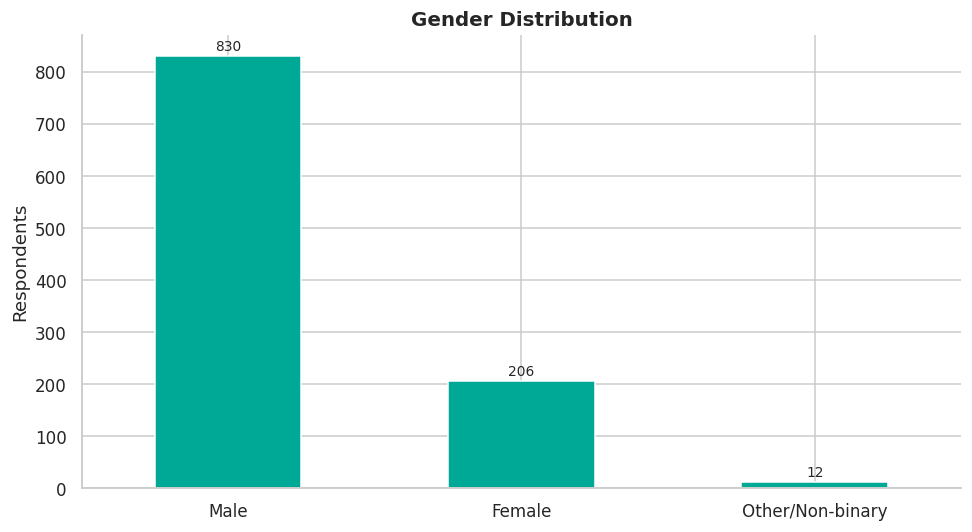

In [13]:
counts = df["Gender_clean"].value_counts()
ax = counts.plot(kind="bar", color=ACCENT, rot=0)
ax.set(title="Gender Distribution", xlabel="", ylabel="Respondents")
bar_labels(ax)
plt.tight_layout(); plt.show()
print((counts / counts.sum() * 100).round(1).astype(str) + " %")

> **Insight:** The sample is **male-dominated** (nearly 4 in 5). Gender-based comparisons should be read with this imbalance in mind, and findings may not generalise evenly to XYZ's own workforce.

### 4.3 Treatment-seeking overall

treatment
No     536
Yes    512
Name: count, dtype: int64


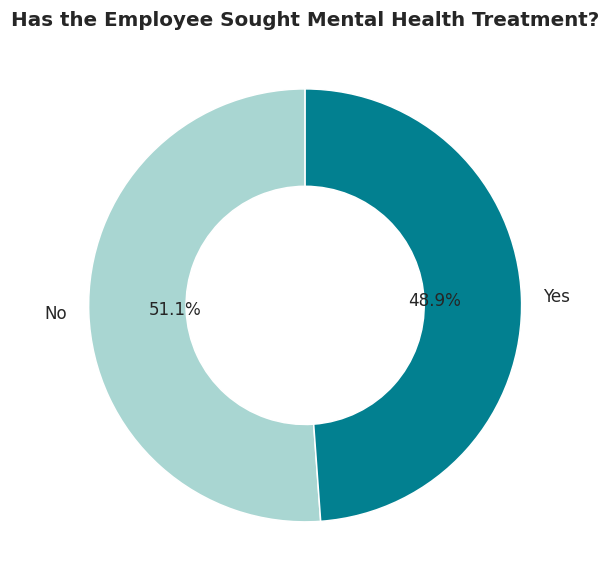

In [14]:
counts = df["treatment"].value_counts()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=["#A9D6D2", PRIMARY], wedgeprops=dict(width=0.45, edgecolor="white"),
       textprops={"fontsize": 11})
ax.set_title("Has the Employee Sought Mental Health Treatment?")
plt.tight_layout(); plt.show()
print(counts)

> **Insight:** **48.9%** (512 of 1,048) have already sought treatment. This is a mainstream issue affecting close to half the sampled workforce, which supports organisation-wide support rather than opt-in-only programmes.

### 4.4 Family history vs. treatment

family_history: chi2 = 153.5, dof = 1, p = 2.9e-35


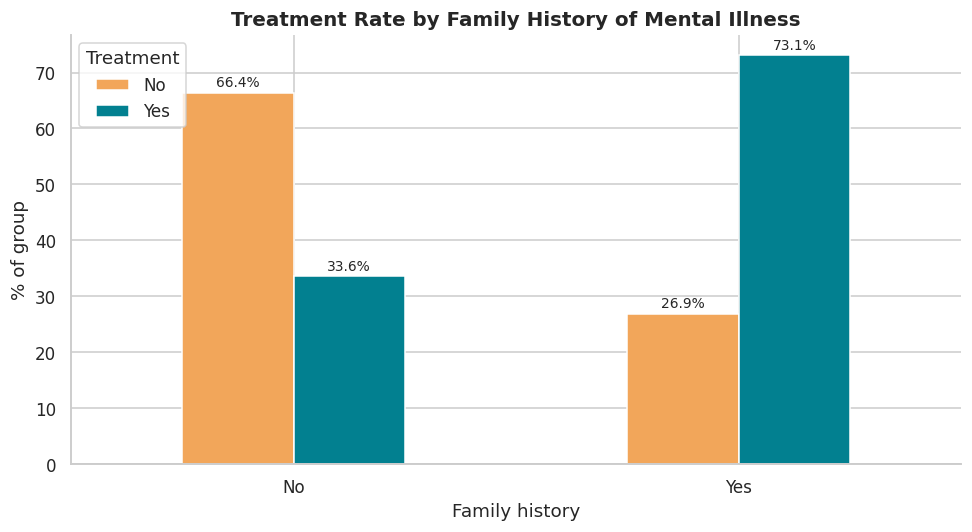

,n,treatment_rate_%
family_history,,
No,643,33.59
Yes,405,73.09


In [15]:
ct = pd.crosstab(df["family_history"], df["treatment"], normalize="index") * 100
ax = ct.plot(kind="bar", color=[WARM, PRIMARY], rot=0)
ax.set(title="Treatment Rate by Family History of Mental Illness",
       xlabel="Family history", ylabel="% of group")
ax.legend(title="Treatment", loc="upper left")
bar_labels(ax, "{:.1f}%")
plt.tight_layout(); plt.show()

display(treatment_rate(df, "family_history"))
chi2_report(df, "family_history")

> **Insight:** Employees with a family history seek treatment at **73.1%**, more than **2x** the rate of those without (**33.6%**, chi-square p < 0.001). Among the factors an employer can actually ask about up front, it is the clearest link.

### 4.5 Work interference vs. treatment

work_interfere_clean: chi2 = 500.8, dof = 4, p = 4.5e-107


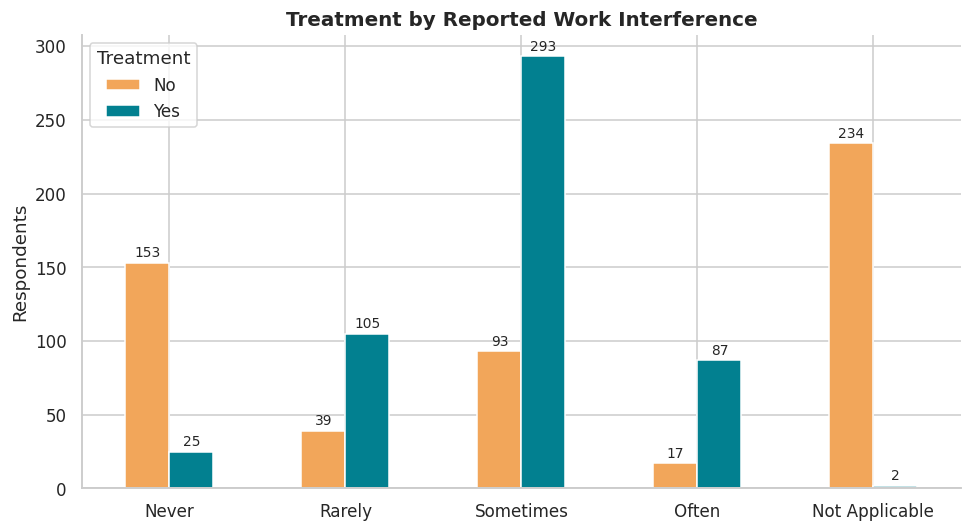

,n,treatment_rate_%
work_interfere_clean,,
Never,178,14.04
Rarely,144,72.92
Sometimes,386,75.91
Often,104,83.65
Not Applicable,236,0.85


In [16]:
order_wi = ["Never", "Rarely", "Sometimes", "Often", "Not Applicable"]
ct = pd.crosstab(df["work_interfere_clean"], df["treatment"]).reindex(order_wi)
ax = ct.plot(kind="bar", color=[WARM, PRIMARY], rot=0)
ax.set(title="Treatment by Reported Work Interference", xlabel="", ylabel="Respondents")
ax.legend(title="Treatment")
bar_labels(ax)
plt.tight_layout(); plt.show()

display(treatment_rate(df, "work_interfere_clean", order_wi))
chi2_report(df, "work_interfere_clean")

> **Insight:** Treatment rates are **73% (Rarely), 76% (Sometimes) and 84% (Often)**, versus only **14% for Never**. Note that *Not Applicable* (no condition reported) is ~1%, so this variable is partly tautological with the target; read it as a *severity* signal among those with a condition rather than an independent risk factor.

### 4.6 Company size vs. treatment

no_employees_clean: chi2 = 7.6, dof = 5, p = 0.18


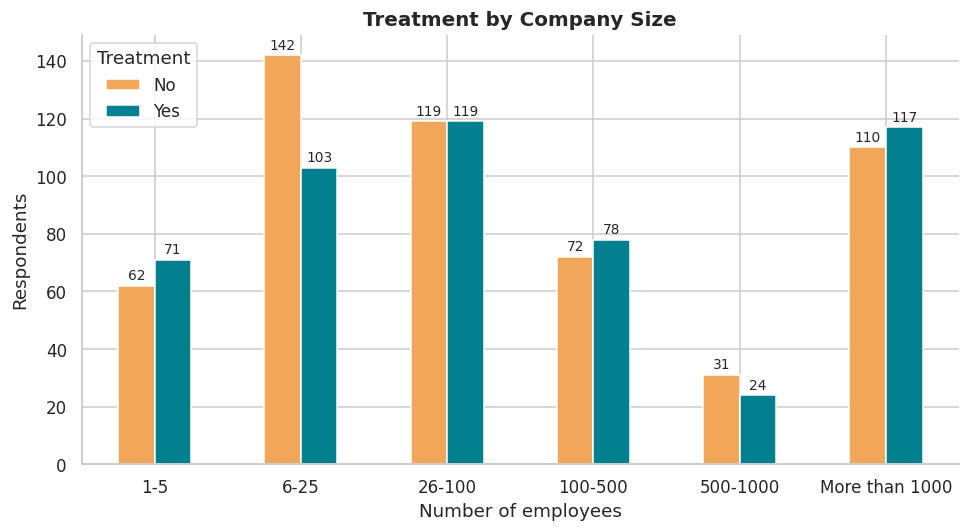

,n,treatment_rate_%
no_employees_clean,,
1-5,133,53.38
6-25,245,42.04
26-100,238,50.00
100-500,150,52.00
500-1000,55,43.64
More than 1000,227,51.54


In [17]:
ct = pd.crosstab(df["no_employees_clean"], df["treatment"])
ax = ct.plot(kind="bar", color=[WARM, PRIMARY], rot=0)
ax.set(title="Treatment by Company Size", xlabel="Number of employees", ylabel="Respondents")
ax.legend(title="Treatment")
bar_labels(ax)
plt.tight_layout(); plt.show()

display(treatment_rate(df, "no_employees_clean", ORDER_SIZE))
chi2_report(df, "no_employees_clean")

> **Insight:** Treatment-seeking is **fairly stable across company sizes**, ranging from ~42% to ~53% with no statistically significant difference (p = 0.18). Structure matters less than culture.

### 4.7 Benefits awareness vs. treatment

benefits: chi2 = 50.8, dof = 2, p = 9.3e-12


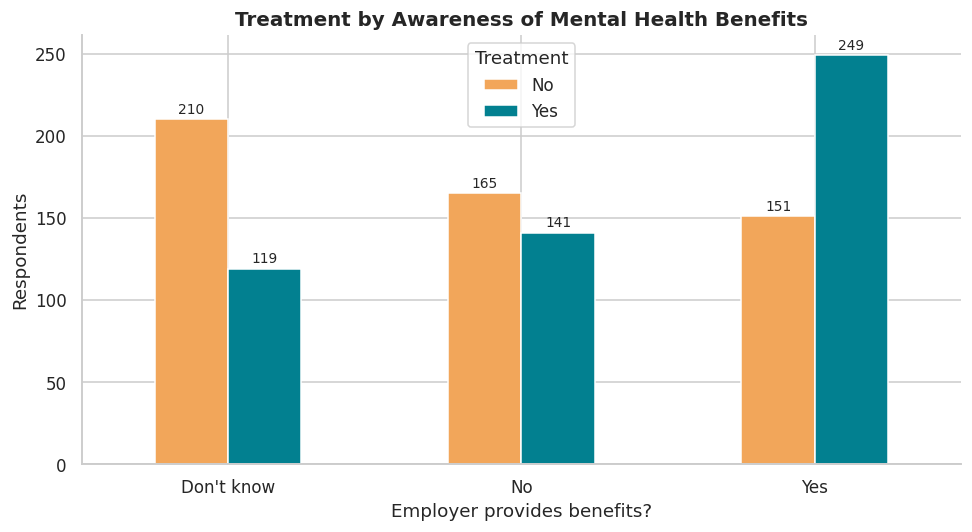

,n,treatment_rate_%
benefits,,
Don't know,329,36.17
No,306,46.08
Yes,400,62.25


In [18]:
ct = pd.crosstab(df["benefits"], df["treatment"])
ax = ct.plot(kind="bar", color=[WARM, PRIMARY], rot=0)
ax.set(title="Treatment by Awareness of Mental Health Benefits", xlabel="Employer provides benefits?", ylabel="Respondents")
ax.legend(title="Treatment")
bar_labels(ax)
plt.tight_layout(); plt.show()

display(treatment_rate(df, "benefits"))
chi2_report(df, "benefits")

> **Insight:** Employees who **know** their employer offers benefits seek treatment at ~**62%**, versus ~**36%** among those who answer *Don't know*. Communicating existing benefits may matter as much as adding new ones.

### 4.8 Respondent geography

Country
United States     61.5 %
United Kingdom    14.6 %
Canada             6.1 %
Name: proportion, dtype: str


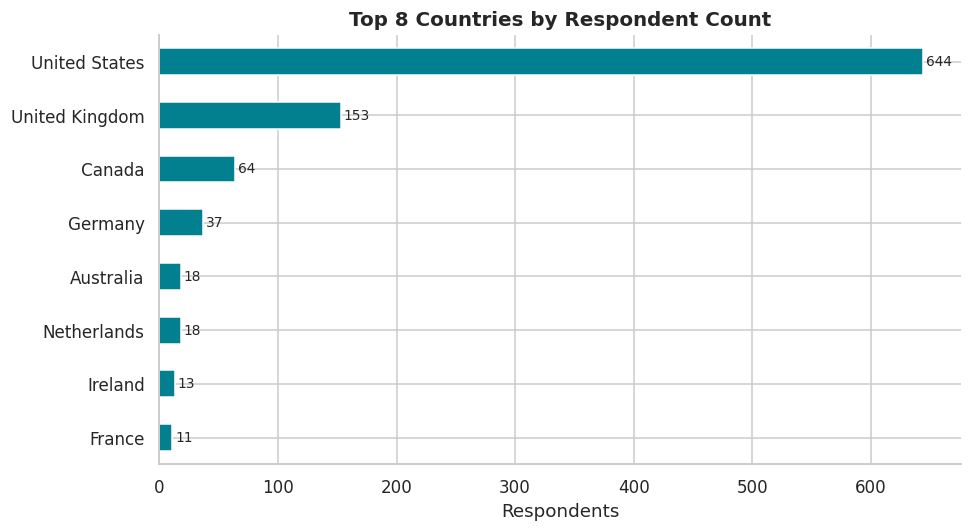

In [19]:
top = df["Country"].value_counts().head(8)
ax = top.sort_values().plot(kind="barh", color=PRIMARY)
ax.set(title="Top 8 Countries by Respondent Count", xlabel="Respondents", ylabel="")
bar_labels(ax)
plt.tight_layout(); plt.show()
print((df["Country"].value_counts(normalize=True).head(3) * 100).round(1).astype(str) + " %")

> **Insight:** **~61% US** and **~15% UK**. Healthcare-access and cultural differences between regions may confound some patterns, so validate against XYZ's own locations.

### 4.9 Gender and age vs. treatment

Gender_clean: chi2 = 48.4, dof = 2, p = 3e-11


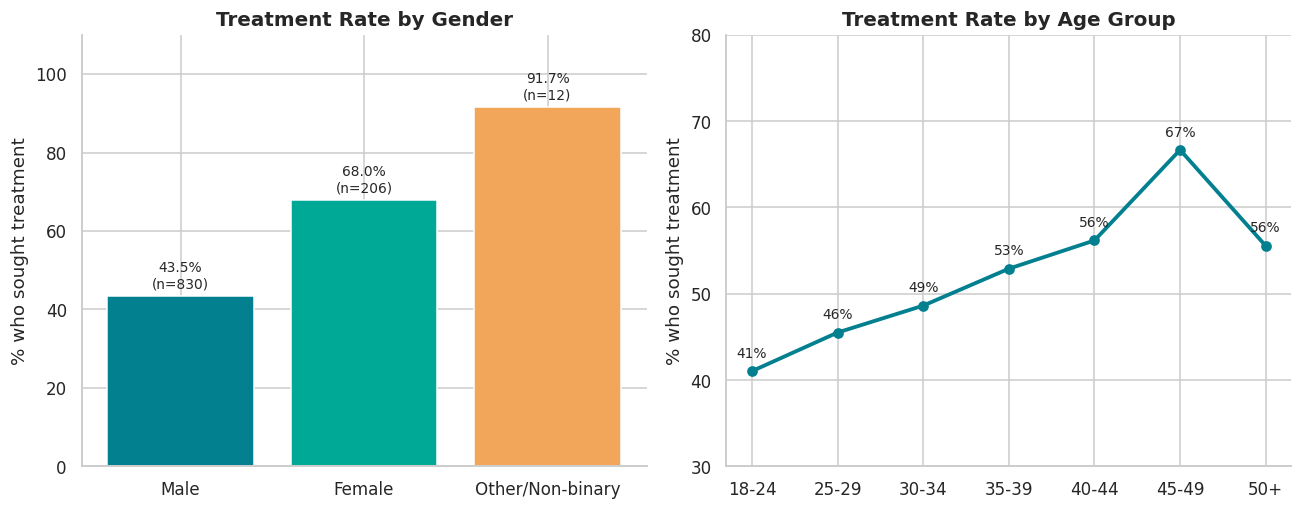

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

g = treatment_rate(df, "Gender_clean", ["Male", "Female", "Other/Non-binary"])
axes[0].bar(g.index, g["treatment_rate_%"], color=[PRIMARY, ACCENT, WARM])
axes[0].bar_label(axes[0].containers[0], labels=[f"{v:.1f}%\n(n={n})" for v, n in zip(g["treatment_rate_%"], g["n"])], padding=3, fontsize=9)
axes[0].set(title="Treatment Rate by Gender", ylabel="% who sought treatment", ylim=(0, 110))

a = treatment_rate(df, "age_bin", labels)
axes[1].plot(a.index.astype(str), a["treatment_rate_%"], marker="o", color=PRIMARY, lw=2.5)
for x, y in zip(a.index.astype(str), a["treatment_rate_%"]):
    axes[1].annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
axes[1].set(title="Treatment Rate by Age Group", ylabel="% who sought treatment", ylim=(30, 80))
plt.tight_layout(); plt.show()
chi2_report(df, "Gender_clean")

> **Insight:** Women (**68%**) are far more likely than men (**43.5%**) to have sought treatment, and treatment-seeking **rises steadily with age** (41% at 18-24 to 55-67% at 40+). The *Other/Non-binary* group is only 12 people, so its 92% is indicative, not conclusive.

### 4.10 Employer support vs. treatment

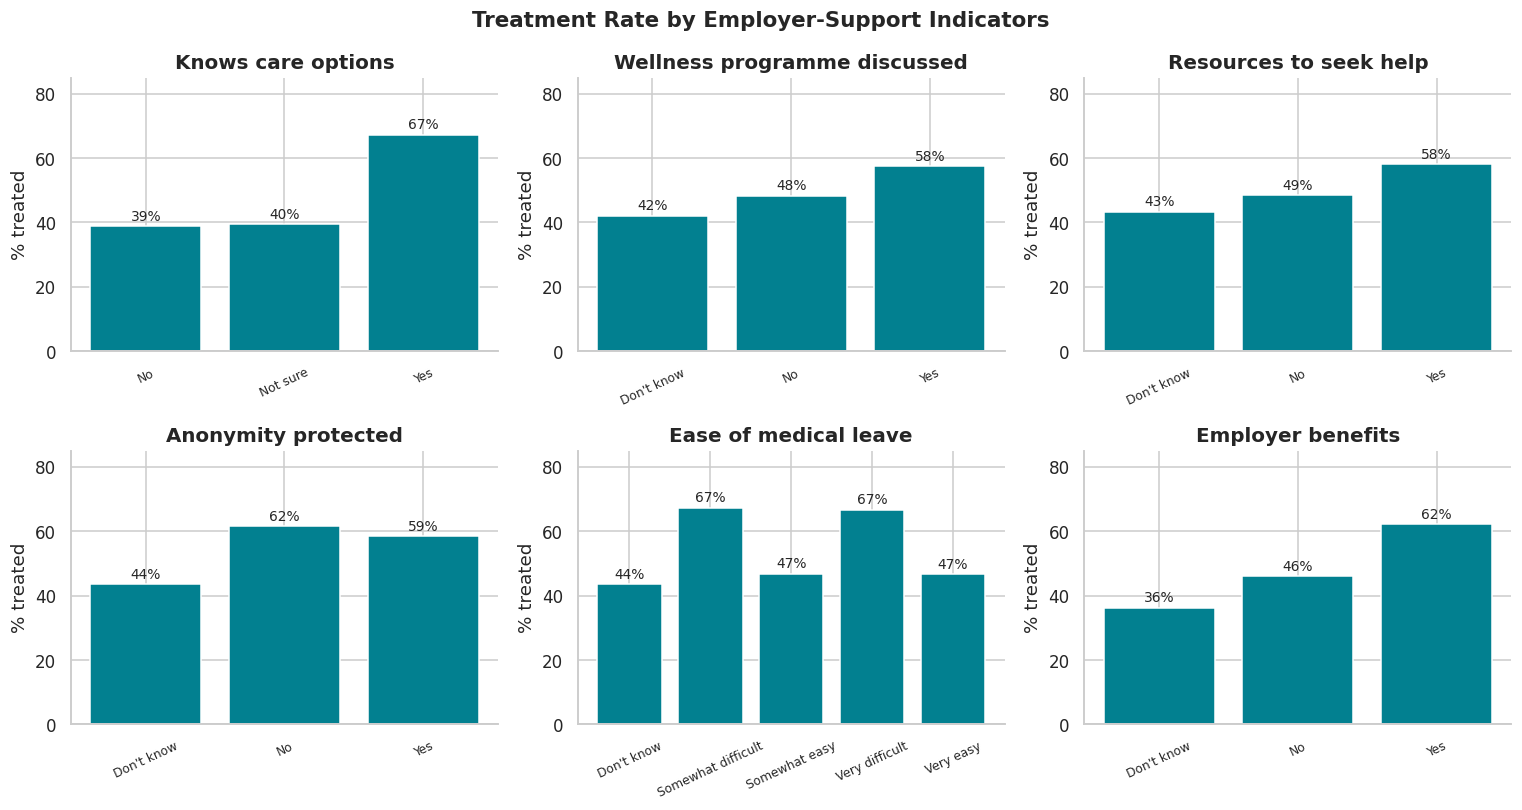

In [21]:
support = {"care_options": "Knows care options", "wellness_program": "Wellness programme discussed",
           "seek_help": "Resources to seek help", "anonymity": "Anonymity protected",
           "leave": "Ease of medical leave", "benefits": "Employer benefits"}
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, (col, title) in zip(axes.ravel(), support.items()):
    t = treatment_rate(df, col)
    ax.bar(t.index, t["treatment_rate_%"], color=PRIMARY)
    ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=2, fontsize=9)
    ax.set(title=title, ylim=(0, 85), ylabel="% treated")
    ax.tick_params(axis="x", rotation=25, labelsize=8)
plt.suptitle("Treatment Rate by Employer-Support Indicators", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

> **Insight:** Employees who **know their care options** seek treatment at **67%**, versus ~**39%** for those who say *No* or *Not sure*. Knowing what exists is the single biggest employer-side lever in the data. Note that people who already use care may simply be better informed, so this is an association, not proof that awareness *causes* treatment.

### 4.11 Stigma and disclosure vs. treatment

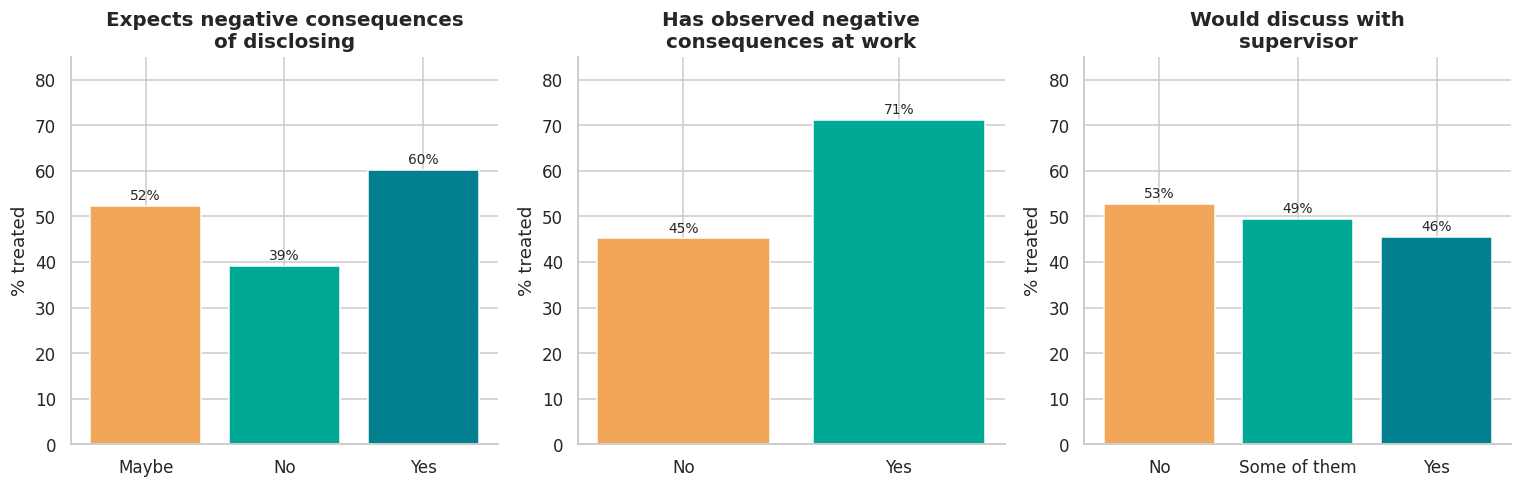

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
panels = [("mental_health_consequence", "Expects negative consequences\nof disclosing"),
          ("obs_consequence", "Has observed negative\nconsequences at work"),
          ("supervisor", "Would discuss with\nsupervisor")]
for ax, (col, title) in zip(axes, panels):
    t = treatment_rate(df, col)
    ax.bar(t.index, t["treatment_rate_%"], color=[WARM, ACCENT, PRIMARY][: len(t)])
    ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=2, fontsize=9)
    ax.set(title=title, ylim=(0, 85), ylabel="% treated")
plt.tight_layout(); plt.show()

> **Insight:** Employees who have **observed negative consequences** for colleagues are treated at **71%** (vs. 45%), and those who fear consequences of disclosure at **60%** (vs. 39%). People who need care are acutely aware of stigma. Willingness to talk to a supervisor is *lower* among those already treated, which supports offering **confidential channels** instead of relying on line managers.

### 4.12 Bonus · Ranking all factors by strength of association
A single view comparing how strongly every categorical survey item relates to treatment, using **Cramer's V** (0 = no association, 1 = perfect).

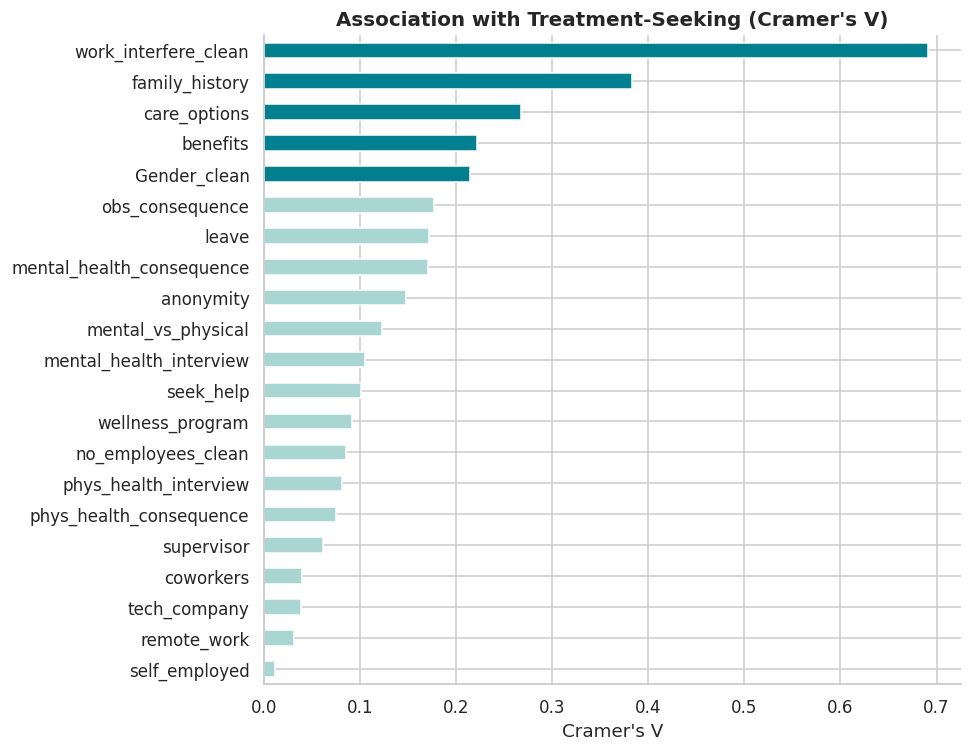

,Cramer's V
work_interfere_clean,0.69
family_history,0.38
care_options,0.27
benefits,0.22
Gender_clean,0.21


In [23]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

candidates = ["family_history", "work_interfere_clean", "benefits", "care_options", "wellness_program",
              "seek_help", "anonymity", "leave", "mental_health_consequence", "phys_health_consequence",
              "coworkers", "supervisor", "mental_health_interview", "phys_health_interview",
              "mental_vs_physical", "obs_consequence", "no_employees_clean", "remote_work",
              "tech_company", "self_employed", "Gender_clean"]

assoc = (pd.Series({c: cramers_v(df[c].astype(str), df["treatment"]) for c in candidates})
           .sort_values())
ax = assoc.plot(kind="barh", color=[PRIMARY if v >= 0.2 else "#A9D6D2" for v in assoc], figsize=(9, 7))
ax.set(title="Association with Treatment-Seeking (Cramer's V)", xlabel="Cramer's V", ylabel="")
plt.tight_layout(); plt.show()
assoc.sort_values(ascending=False).head(5).round(3).to_frame("Cramer's V")

> **Insight:** Work interference (V ~ 0.69) and family history (V ~ 0.38) dominate, followed by knowledge of care options and benefits. Structural factors such as remote work, tech-company status and self-employment sit near zero, reinforcing the main conclusions above.

## 5. Key Insights

| # | Insight | Evidence |
|---|---|---|
| 1 | **Family history** is the strongest independent risk factor for treatment-seeking | 73.1% vs. 33.6% (Cramer's V = 0.38) |
| 2 | **Work interference** tracks very closely with treatment-seeking (strongest overall association), making it a practical check-in cue | 73-84% vs. 14% for *Never* (V = 0.69) |
| 3 | **Awareness of benefits** drives usage more than their mere existence | ~62% vs. ~36% |
| 4 | **Nearly half** of respondents have sought treatment: this is mainstream, not fringe | 48.9% (512 / 1,048) |
| 5 | **Company size and remote work** have little effect: culture matters more than structure | Company size p = 0.18; V < 0.1 |
| 6 | **Knowing care options** is the strongest employer-side signal; **stigma awareness** is high among the treated | 67% vs. ~39%; 71% vs. 45% |
| 7 | Women and older employees are more likely to have sought treatment | 68% vs. 43.5%; 41% to 55%+ by age |
| 8 | The sample skews **young, male and US/UK-based** | Sections 4.1, 4.2, 4.8 |

## 6. Recommendations

1. **Communicate benefits and care options clearly.** Awareness is associated with a ~26-point higher treatment rate (62% vs. 36%), so make existing programmes visible.
2. **Train managers on warning signs.** Self-reported work interference is an actionable cue for a supportive check-in.
3. **Build in proactive check-ins.** With ~49% already seeking support, don't rely on opt-in programmes alone.
4. **Protect anonymity.** Willingness to disclose to supervisors and coworkers varies widely, so offer confidential channels.
5. **Validate on XYZ's own data.** Re-run this analysis on XYZ's internal survey before finalising any programme.

## 7. Limitations & Next Steps

- **Association is not causation.** Findings describe patterns in survey answers, not drivers.
- **Self-reported data** is subject to recall and social-desirability bias.
- **Sample bias:** the respondents skew young, male and US/UK-based, so results may not generalise to XYZ.
- **Gender grouping:** consolidating to three categories is a pragmatic simplification; the *Other/Non-binary* group is very small.
- **Next steps:** build a predictive model (e.g. logistic regression / gradient boosting) to flag employees who may need support, and run the same analysis on XYZ's own survey data.

---
*Prepared for the EDA Project submission · Employee Wellness Analysis*